# 作品タイトル：Prediction Rain
名前：安藤裕基、大島勇希、橋爪勇樹

In [2]:
# 通信とJSONの読み取りに使う標準ライブラリ
import json
from urllib.request import urlopen
from urllib.parse import urlencode

# ① 取得する場所と期間を設定する（柏市の例）

# 緯度
lat = 35.804249

# 経度
lon = 139.797300

# 過去何日分を含めるか
past_days = 3

# 今日を含む予報の日数
forecast_days = 5

# 取得する場所の現地時間を使う
timezone = "auto"

# 欲しい天気の項目を、カンマ区切りの文字列で指定する
daily_fields = (
    "temperature_2m_max,temperature_2m_min,"
    "precipitation_probability_max,rain_sum,showers_sum"
)

# 通信を待つ最大秒数
timeout = 10

# ② 設定した変数をパラメータに渡し、URLを作る
url = "https://api.open-meteo.com/v1/forecast?" + urlencode({
    "latitude": lat, "longitude": lon,
    "daily": daily_fields,
    "past_days": past_days, "forecast_days": forecast_days,
    "timezone": timezone
})

# ③ APIから取得したJSONを、Pythonの辞書に変換する
with urlopen(url, timeout=timeout) as response:
    weather = json.load(response)

# ④ 日別データを表示する（セルの最後の値はprint不要）
weather["daily"]

{'time': ['2026-11-15',
  '2026-11-16',
  '2026-11-17',
  '2026-11-18',
  '2026-11-19',
  '2026-11-20',
  '2026-11-21',
  '2026-11-22'],
 'temperature_2m_max': [13.4, 18.6, 12.9, 19.2, 18.5, 15.9, 13.2, 12.4],
 'temperature_2m_min': [10.8, 11.3, 9.1, 9.3, 9.6, 8.2, 1.6, 3.9],
 'precipitation_probability_max': [100, 47, 100, 100, 6, 0, 0, 2],
 'rain_sum': [9.9, 0.0, 21.1, 25.5, 0.0, 0.0, 0.0, 0.0],
 'showers_sum': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]}

Adachi City 2026-11-19 6 %
Katsushika-ku 2026-11-19 6 %
Hachiōji 2026-11-19 4 %
Kawagoe 2026-11-19 2 %
Kawasaki 2026-11-19 4 %
Koshigaya 2026-11-19 2 %
Saitama 2026-11-19 2 %
Tachikawa 2026-11-19 8 %


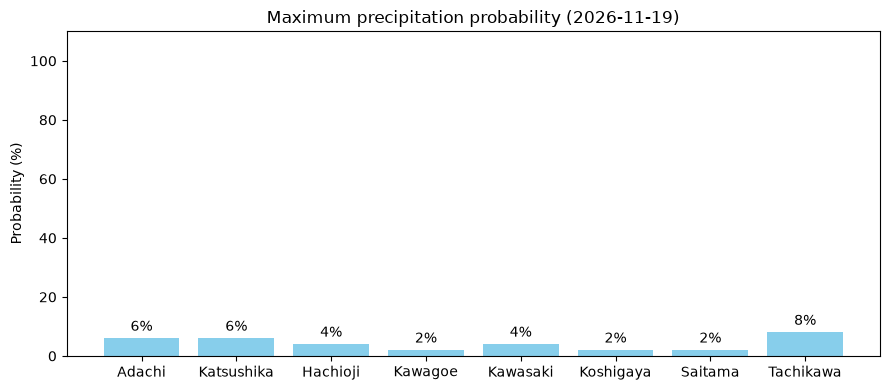

In [3]:
# ① 比べる都市と、APIの取得条件を先に設定する
cities = ["Adachi", "Katsushika", "Hachioji", "Kawagoe", "Kawasaki", "Koshigaya", "Saitama", "Tachikawa"]

# 日本の都市に絞る
country_code = "JP"

# 地名の表示言語
language = "en"

# 各都市の検索候補数
match_count = 1

# 過去何日分を含めるか
city_past_days = 1

# 今日を含む取得日数
forecast_days = 3

# 各都市の現地時間
timezone = "auto"
daily_fields = "precipitation_probability_max"

# 0＝今日、1＝明日
day_offset = 1

# 通信を待つ最大秒数
timeout = 10

# ② 都市ごとに「場所の検索→天気の取得→表示」を繰り返す
city_names = []
chances = []

for city in cities:

    # 都市名から、最初の候補の場所を調べる
    url = "https://geocoding-api.open-meteo.com/v1/search?" + urlencode({
        "name": city, "count": match_count,
        "language": language, "countryCode": country_code
    })
    with urlopen(url, timeout=timeout) as response:
        city_place = json.load(response)["results"][0]

    # 見つかった緯度・経度を、天気APIに渡す
    lat = city_place["latitude"]
    lon = city_place["longitude"]
    url = "https://api.open-meteo.com/v1/forecast?" + urlencode({
        "latitude": lat, "longitude": lon, "daily": daily_fields,
        "past_days": city_past_days, "forecast_days": forecast_days,
        "timezone": timezone
    })
    with urlopen(url, timeout=timeout) as response:
        city_weather = json.load(response)

    # ③ 指定した日の日付と降水確率を表示する
    daily = city_weather["daily"]
    i = city_past_days + day_offset
    chance = daily["precipitation_probability_max"][i]
    print(city_place["name"], daily["time"][i], chance, "%")
    if chance is not None:
        city_names.append(city)
        chances.append(chance)

# ④ 地点ごとの最大降水確率を棒グラフで比較する
import matplotlib.pyplot as plt

if city_names:
    fig, ax = plt.subplots(figsize=(9, 4))
    bars = ax.bar(city_names, chances, color="skyblue")
    ax.bar_label(bars, labels=[f"{value}%" for value in chances], padding=3)
    ax.set_title(f"Maximum precipitation probability ({daily['time'][i]})")
    ax.set_ylabel("Probability (%)")
    ax.set_yticks(range(0, 101, 20))
    ax.set_ylim(0, 110)
    fig.tight_layout()
    plt.show()
else:
    print("No precipitation probability data to plot.")


In [9]:
if chances:
    lowest = min(chances)
    print(f"{daily['time'][i]} の予報")

    for city, chance in zip(city_names, chances):
        if chance == lowest:
            print(f"雨が降りにくそうな場所：{city}（最大降水確率 {chance}%）")
else:
    print("降水確率のデータがありません。")

2026-11-19 の予報
雨が降りにくそうな場所：Kawagoe（最大降水確率 2%）
雨が降りにくそうな場所：Koshigaya（最大降水確率 2%）
雨が降りにくそうな場所：Saitama（最大降水確率 2%）


In [8]:
# ① 選べる日と、終了用の入力を決める

# 0＝今日、1＝明日
day_options = ["0", "1"]

# この文字を入力したら終了
quit_command = "q"
prompt = f"Days ahead {day_options}, {quit_command} = quit: "

# ② 取得済みのデータを使い、最初の入力を受け取る
daily = weather["daily"]
choice = input(prompt)

# ③ 終了コマンドが入力されるまで繰り返す
while choice != quit_command:
    if choice in day_options:

        # 入力は文字列なので、計算する前にintで整数にする
        i = past_days + int(choice)

    if 0 <= i < len(daily["time"]):
        print(daily["time"][i],
          daily["temperature_2m_max"][i], "°C")

    # 入力を更新し、次のwhileの条件で確かめる
    choice = input(prompt)

2026-11-18 19.2 °C
2026-11-19 18.5 °C


In [5]:
# ① 表示する日と、文字の棒の見た目を決める

# 0＝今日から、1＝明日から
start_day = 0

# 棒全体の文字数（正の整数）
bar_width = 20

# 確率に応じて塗る部分
filled = "█"

# 残りの部分
empty = "░"

# ② 100%を棒の長さで割り、1文字分の割合を求める
daily = weather["daily"]
points_per_block = 100 / bar_width
print("Maximum precipitation probability")
print("Each block is about", points_per_block, "percentage points.")

# ③ 各日の降水確率を、文字の棒で表示する
for i in range(past_days + start_day, len(daily["time"])):
    chance = daily["precipitation_probability_max"][i]
    if chance is None:
        print(daily["time"][i], "No data")
    else:

        # 文字数を丸め、塗る部分と残りの部分をつなぐ
        blocks = round(chance / points_per_block)
        bar = filled * blocks + empty * (bar_width - blocks)

        # 丸める前の正確な%も、棒の横に表示する
        print(f'{daily["time"][i]} |{bar}| {chance:3}%')

Maximum precipitation probability
Each block is about 5.0 percentage points.
2026-11-18 |████████████████████| 100%
2026-11-19 |█░░░░░░░░░░░░░░░░░░░|   6%
2026-11-20 |░░░░░░░░░░░░░░░░░░░░|   0%
2026-11-21 |░░░░░░░░░░░░░░░░░░░░|   0%
2026-11-22 |░░░░░░░░░░░░░░░░░░░░|   2%


機能：雨が降りにくそうな場所をピックアップする機能です。この効果として雨が降らないからこの場所に行こう！などの提案、予定を決めやすくなると思います。

改善：雨が全国的に降って遊ぶ場所がなくなってときの代案も出せるようにしたい。    